## Análisis de Rotación de Empleados con Máquinas de Soporte Vectorial (SVM)

**Objetivo:** Analizar porqué los empleados deciden irse con la competencia usando modelos predictivos SVM con 4 kernels diferentes.

**Variables:**
- satisfaction_level, last_evaluation, number_project, average_montly_hours, time_spend_company
- work_accident (1=Sí,0=No), promotion_last_5years
- sales: departamento, salary: categoría salarial
- left: variable objetivo (1=se va)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score
import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 22")

df = pd.read_csv('recursos_humanos.csv')
df.columns = [c.strip() for c in df.columns]
df.rename(columns={'Work_accident':'work_accident'}, inplace=True)
print(df.shape)
df.head()

(14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


left
0    11428
1     3571
Name: count, dtype: int64
sales
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64
salary
low       7316
medium    6446
high      1237
Name: count, dtype: int64


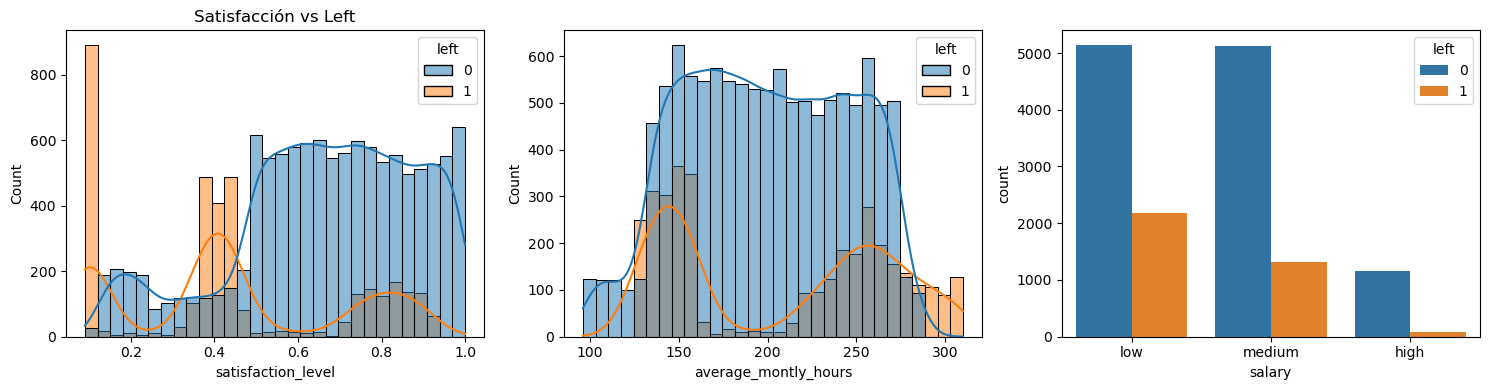

In [2]:
# Balance de clases y distribuciones
print(df['left'].value_counts())
print(df['sales'].value_counts())
print(df['salary'].value_counts())
df.describe()

# Visualización rápida
fig, axes = plt.subplots(1,3, figsize=(15,4))
sns.histplot(data=df, x='satisfaction_level', hue='left', kde=True, ax=axes[0])
axes[0].set_title('Satisfacción vs Left')
sns.histplot(data=df, x='average_montly_hours', hue='left', kde=True, ax=axes[1])
sns.countplot(data=df, x='salary', hue='left', ax=axes[2])
plt.tight_layout()
plt.show()

In [4]:
# Recodificación de variables categóricas con pd.get_dummies
# sales y salary son nominales -> one-hot encoding
# Se mantiene drop_first=False para conservar interpretabilidad completa, aunque drop_first=True también sería válido
df_encoded = pd.get_dummies(df, columns=['sales','salary'], drop_first=False)
print(df_encoded.head())
print(f"Columnas tras dummies: {df_encoded.columns.tolist()}")

X = df_encoded.drop('left', axis=1)
y = df_encoded['left']
feature_columns = X.columns.tolist()

   satisfaction_level  last_evaluation  number_project  average_montly_hours  \
0                0.38             0.53               2                   157   
1                0.80             0.86               5                   262   
2                0.11             0.88               7                   272   
3                0.72             0.87               5                   223   
4                0.37             0.52               2                   159   

   time_spend_company  work_accident  left  promotion_last_5years  sales_IT  \
0                   3              0     1                      0     False   
1                   6              0     1                      0     False   
2                   4              0     1                      0     False   
3                   5              0     1                      0     False   
4                   3              0     1                      0     False   

   sales_RandD  ...  sales_hr  sales_managem

In [5]:
# Train-test split estratificado 70-30
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Escalado: FUNDAMENTAL para SVM porque usa distancias
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Train: {X_train_scaled.shape}, Test: {X_test_scaled.shape}")

Train: (10499, 20), Test: (4500, 20)



==================== KERNEL: linear ====================
Accuracy: 0.7742
              precision    recall  f1-score   support

Se queda (0)       0.80      0.93      0.86      3429
   Se va (1)       0.55      0.26      0.36      1071

    accuracy                           0.77      4500
   macro avg       0.68      0.60      0.61      4500
weighted avg       0.74      0.77      0.74      4500


==================== KERNEL: rbf ====================
Accuracy: 0.9487
              precision    recall  f1-score   support

Se queda (0)       0.97      0.97      0.97      3429
   Se va (1)       0.89      0.89      0.89      1071

    accuracy                           0.95      4500
   macro avg       0.93      0.93      0.93      4500
weighted avg       0.95      0.95      0.95      4500


==================== KERNEL: poly ====================
Accuracy: 0.9340
              precision    recall  f1-score   support

Se queda (0)       0.94      0.97      0.96      3429
   Se va (1)     

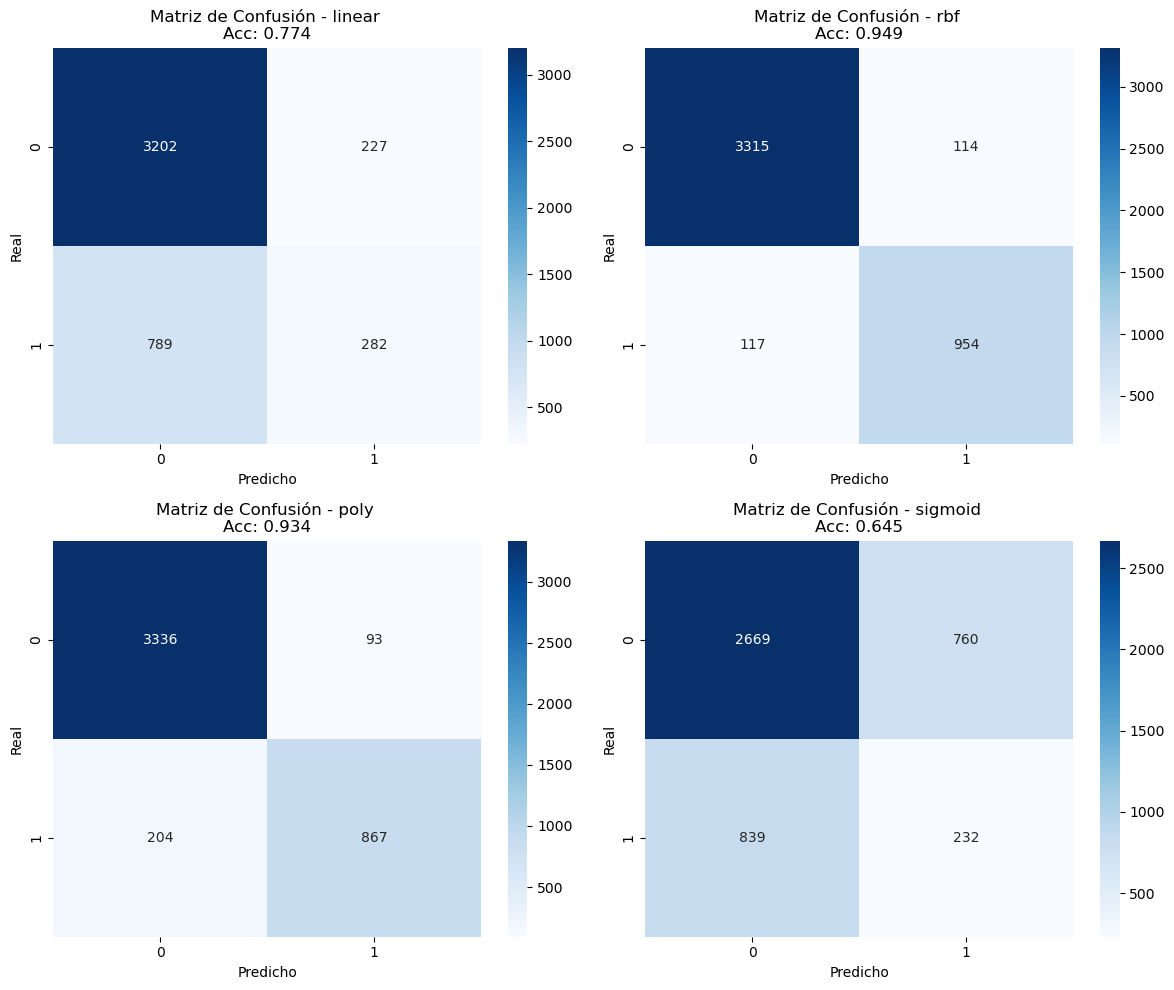

,kernel,accuracy,precision_clase1,recall_clase1,f1_clase1
0,linear,0.774222,0.554028,0.263305,0.356962
1,rbf,0.948667,0.893258,0.890756,0.892006
2,poly,0.934000,0.903125,0.809524,0.853767
3,sigmoid,0.644667,0.233871,0.216620,0.224915


In [6]:
kernels = ['linear','rbf','poly','sigmoid']
results = {}

for kernel in kernels:
    print(f"\n{'='*20} KERNEL: {kernel} {'='*20}")
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Se queda (0)','Se va (1)']))

    results[kernel] = {'model':model, 'cm':cm, 'acc':acc, 'y_pred':y_pred}

# Visualización matrices
fig, axes = plt.subplots(2,2, figsize=(12,10))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    sns.heatmap(results[kernel]['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'Matriz de Confusión - {kernel} \nAcc: {results[kernel]["acc"]:.3f}')
    axes[i].set_xlabel('Predicho')
    axes[i].set_ylabel('Real')
plt.tight_layout()
plt.show()

# Comparativa
import pandas as pd
summary = []
for k,v in results.items():
    r = classification_report(y_test, v['y_pred'], output_dict=True)
    summary.append({
        'kernel':k,
        'accuracy':r['accuracy'],
        'precision_clase1':r['1']['precision'],
        'recall_clase1':r['1']['recall'],
        'f1_clase1':r['1']['f1-score']
    })
pd.DataFrame(summary)

# Función para predecir nuevo empleado

In [7]:
# Función para predecir nuevo empleado
def predecir_empleado(satisfaction_level, last_evaluation, number_project,
                      average_montly_hours, time_spend_company,
                      work_accident, promotion_last_5years,
                      sales_dept, salary_cat):
    # Crear un df base con todas las columnas a 0
    input_dict = {col:0 for col in feature_columns}
    # Numéricas
    input_dict['satisfaction_level']=satisfaction_level
    input_dict['last_evaluation']=last_evaluation
    input_dict['number_project']=number_project
    input_dict['average_montly_hours']=average_montly_hours
    input_dict['time_spend_company']=time_spend_company
    input_dict['work_accident']=work_accident
    input_dict['promotion_last_5years']=promotion_last_5years
    # Categóricas
    sales_col = f'sales_{sales_dept}'
    salary_col = f'salary_{salary_cat}'
    if sales_col in input_dict:
        input_dict[sales_col]=1
    else:
        print(f"Advertencia: departamento {sales_dept} no visto")
    if salary_col in input_dict:
        input_dict[salary_col]=1

    X_new = pd.DataFrame([input_dict])[feature_columns]
    X_new_scaled = scaler.transform(X_new)

    for k in kernels:
        pred = results[k]['model'].predict(X_new_scaled)[0]
        proba_approx = results[k]['model'].decision_function(X_new_scaled)[0] if hasattr(results[k]['model'], 'decision_function') else 'N/A'
        print(f"Kernel {k:8s} -> Predicción left={pred} ({'SE VA' if pred==1 else 'SE QUEDA'}) | decision={proba_approx:.3f}" if isinstance(proba_approx, float) else f"Kernel {k} -> {pred}")
    return X_new

# CASO CLÁSICO MOOC - Empleado de alto riesgo
# Basado en fila típica del dataset: perfil insatisfecho y sobre-trabajado
print("=== CASO 1: Empleado alto riesgo (clásico MOOC que abandona) ===")
predecir_empleado(
    satisfaction_level=0.11,
    last_evaluation=0.88,
    number_project=7,
    average_montly_hours=272,
    time_spend_company=4,
    work_accident=0,
    promotion_last_5years=0,
    sales_dept='sales',
    salary_cat='medium'
)

print("\n=== CASO 2: Empleado bajo riesgo (satisfecho, estable) ===")
predecir_empleado(
    satisfaction_level=0.85,
    last_evaluation=0.72,
    number_project=4,
    average_montly_hours=200,
    time_spend_company=3,
    work_accident=0,
    promotion_last_5years=0,
    sales_dept='technical',
    salary_cat='medium'
)

print("\n=== CASO 3: Empleado del enunciado original primera fila (0.38,0.53) ===")
predecir_empleado(
    satisfaction_level=0.5,
    last_evaluation=0.75,
    number_project=4,
    average_montly_hours=200,
    time_spend_company=4,
    work_accident=0,
    promotion_last_5years=0,
    sales_dept='sales',
    salary_cat='medium'
)


=== CASO 1: Empleado alto riesgo (clásico MOOC que abandona) ===
Kernel linear   -> Predicción left=1 (SE VA) | decision=0.481
Kernel rbf      -> Predicción left=1 (SE VA) | decision=2.351
Kernel poly     -> Predicción left=1 (SE VA) | decision=1.388
Kernel sigmoid  -> Predicción left=0 (SE QUEDA) | decision=-4.634

=== CASO 2: Empleado bajo riesgo (satisfecho, estable) ===
Kernel linear   -> Predicción left=0 (SE QUEDA) | decision=-1.883
Kernel rbf      -> Predicción left=0 (SE QUEDA) | decision=-2.461
Kernel poly     -> Predicción left=0 (SE QUEDA) | decision=-1.174
Kernel sigmoid  -> Predicción left=0 (SE QUEDA) | decision=-12.201

=== CASO 3: Empleado del enunciado original primera fila (0.38,0.53) ===
Kernel linear   -> Predicción left=0 (SE QUEDA) | decision=-0.696
Kernel rbf      -> Predicción left=0 (SE QUEDA) | decision=-1.780
Kernel poly     -> Predicción left=0 (SE QUEDA) | decision=-1.137
Kernel sigmoid  -> Predicción left=1 (SE VA) | decision=1.314


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.5,0.75,4,200,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
